# 01 · Build sim_v1

Code: `data/sim_v1/` (`config.py` holds the settings, `calibrate.py` tunes them to NPCI, `generate.py` builds the world).
This notebook runs the three steps and shows what comes out:
1. **Calibrate:** fit the amount and P2P/P2M settings to the real NPCI numbers.
2. **Generate:** build a *train* world (many scams, to learn from) and an *eval* world (a realistic scam rate, to test on).
3. **Look inside:** check that the scams, mules and phone signals behave the way they were designed to.

In [1]:
import json, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd().parents[1] if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path[:0] = [str(ROOT / 'backend'), str(ROOT / 'ml'), str(ROOT / 'data')]
pd.set_option('display.precision', 3); pd.set_option('display.max_colwidth', 80); plt.rcParams['figure.figsize'] = (9, 3.6)
from dataclasses import asdict
from sim_v1 import calibrate, config, generate
OUT = ROOT / 'data/sim_v1_out'

c:\Users\nikks\Downloads\ruko_01\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Calibrate to NPCI
Optuna tries 200 settings for the amount distributions (separate for P2P and merchant payments) and keeps the one closest to NPCI. It runs in a few seconds.

In [2]:
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):
    sys.argv = ['calibrate', '--trials', '200']; calibrate.main()
cal = json.loads((ROOT / 'data/sim_v1/calibrated.json').read_text())
pd.DataFrame({'NPCI target': cal['targets'], 'sim_v1 achieved': cal['achieved']})

,NPCI target,sim_v1 achieved
p2m_share_of_volume,0.633,0.623
p2m_share_of_value,0.302,0.299
avg_ticket_p2p_inr,2320.000,2216.410
avg_ticket_p2m_inr,582.000,574.000
p2m_share_below_500,0.860,0.846
p2p_share_below_500,0.590,0.607


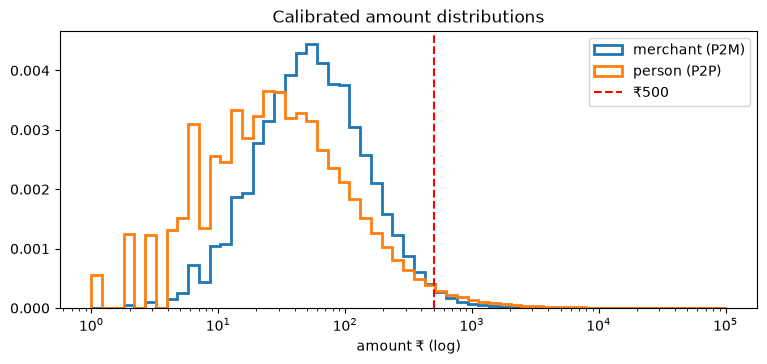

In [3]:
cfg = config.load()
a = generate.lognormal_mix(np.random.default_rng(0), 100_000, cfg.p2m_bulk_median, cfg.p2m_bulk_sigma, cfg.p2m_tail_median, cfg.p2m_tail_sigma, cfg.p2m_tail_weight)
b = generate.lognormal_mix(np.random.default_rng(1), 100_000, cfg.p2p_bulk_median, cfg.p2p_bulk_sigma, cfg.p2p_tail_median, cfg.p2p_tail_sigma, cfg.p2p_tail_weight)
bins = np.logspace(0, 5, 60)
plt.hist(a, bins, histtype='step', lw=2, density=True, label='merchant (P2M)'); plt.hist(b, bins, histtype='step', lw=2, density=True, label='person (P2P)')
plt.axvline(500, color='red', ls='--', label='₹500'); plt.xscale('log'); plt.xlabel('amount ₹ (log)'); plt.legend(); plt.title('Calibrated amount distributions'); plt.show()

**Inference:** all 6 NPCI numbers land inside tolerance:
- P2M share: 62.3% (real 63.3%);
- merchant payments under ₹500: 84.6% (real 86%);
- average P2P payment: ₹2,216 (real ₹2,320).

The chart shows why two shapes are needed per payment type: a big pile of small payments, plus a tail of large ones (rent, gadgets, family transfers). A single bell curve can't hit both "86% under ₹500" and "average ₹582" at once.

## 2. Generate the train and eval worlds
Both use the same code and settings. Only the share of scammed users differs: 5% in train, 0.4% in eval. The eval world also uses a different random seed and is bigger (10,000 users), so it's a genuinely new world with enough scams to measure.

In [4]:
W = {}
for world, seed, users in (('train', 7, 3000), ('eval', 11, 10000)):
    c = config.load(world=world, seed=seed, n_users=users)
    W[world] = generate.build(c); generate.write(W[world], c, OUT / world)
pd.DataFrame({w: {'users': len(t['users']), 'payments': len(t['payments']), 'journeys': len(t['journeys']),
                  'scam payments': int(t['payments'].label_is_scam.sum()),
                  'scam % of user payments': 100 * t['payments'].label_is_scam.sum() / t['payments'].user_id.notna().sum()}
              for w, t in W.items()})

,train,eval
users,3000.000,1.000e+04
payments,298305.000,1.021e+06
journeys,150.000,4.000e+01
scam payments,434.000,1.240e+02
scam % of user payments,0.146,1.221e-02


**Inference:**
- **Train world:** 150 scam journeys and 434 scam payments, about 6× more than `data/sim` (23 journeys, 77 payments). Enough to train on.
- **Eval world:** 0.012% of payments are scams, close to real-world rates. Its 40 journeys and 124 scam payments are what we test on.

## 3. What is inside
### 3a. Payment types (`flow`)
`normal` = everyday life. `rent` and `big_new_payee` are **hard negatives**: honest payments that look like scams. `scam` = victim pays a mule. `scam_external` = victims outside our users pay the same mules. `mule_forward` = mule passes money on to cash-out accounts.

In [5]:
P = W['train']['payments']
P.groupby('flow').agg(payments=('amount', 'size'), median_amount=('amount', 'median'), typed_share=('entry_method', lambda s: (s == 'typed').mean())).sort_values('payments', ascending=False)

,payments,median_amount,typed_share
flow,,,
normal,294374,175.2,0.132
rent,1464,12000.0,0.500
mule_forward,1077,10852.0,1.000
scam_external,770,15352.5,1.000
scam,434,8013.0,0.853
big_new_payee,186,15500.0,1.000


**Inference:**
- **Normal life** dominates, with a median of ₹175.
- **Hard negatives look like scams on purpose:** rent and big first-time payments have medians of ₹12,000–15,500 and are often typed by hand. Without them, "large + typed" would be an easy scam rule.
- **Mules get a lot of extra traffic:** each one receives money from outside victims (770 payments) and forwards most of it on (1,077 payments). That's the money flow the backend's payee features look for.

### 3b. Scam journeys by playbook
Each playbook has its own pattern: digital arrest pays a lot within hours; task job and trading climb a ladder over days.

In [6]:
J = W['train']['journeys']; S = P[P.flow == 'scam']
span = S.groupby('journey_id').ts.agg(lambda t: (t.max() - t.min()).total_seconds() / 86400)
J2 = J.assign(span_days=J.journey_id.map(span), first_amount=J.journey_id.map(S.groupby('journey_id').amount.first()))
J2.groupby('playbook').agg(journeys=('journey_id', 'size'), payments_avg=('n_payments', 'mean'), first_payment_median=('first_amount', 'median'),
                           total_median=('total_paid', 'median'), span_days_median=('span_days', 'median'))

,journeys,payments_avg,first_payment_median,total_median,span_days_median
playbook,,,,,
digital_arrest,29,2.414,41981.0,105011.0,0.229
fake_customer_care,22,2.091,7032.5,22656.5,0.150
fake_kyc_apk,33,1.424,6573.0,9484.0,0.000
refund_qr,11,1.545,3632.0,7667.0,0.052
task_job,29,5.138,811.0,8819.0,4.070
trading_group,26,4.038,23661.0,103417.5,12.440


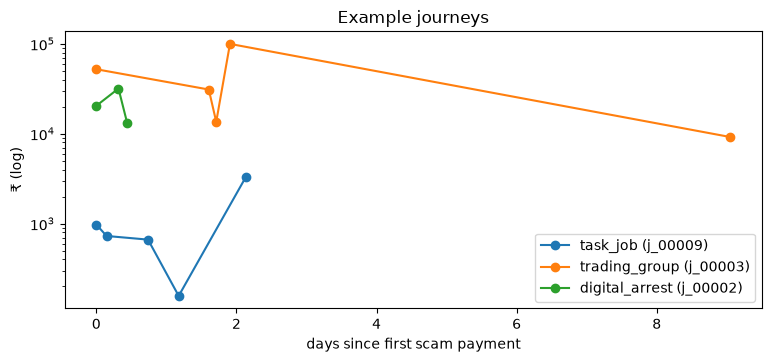

In [7]:
fig, ax = plt.subplots()
for pb in ('task_job', 'trading_group', 'digital_arrest'):
    jid = J2[(J2.playbook == pb) & (J2.n_payments >= 3)].journey_id.iloc[0]
    s = S[S.journey_id == jid]; d = (s.ts - s.ts.min()).dt.total_seconds() / 86400
    ax.plot(d, s.amount, marker='o', label=f'{pb} ({jid})')
ax.set_yscale('log'); ax.set_xlabel('days since first scam payment'); ax.set_ylabel('₹ (log)'); ax.legend(); ax.set_title('Example journeys'); plt.show()

**Inference:** each playbook has its own fingerprint:
- **Task job** starts small (median first payment ₹811) and climbs over about 4 days.
- **Trading group** climbs over about 12 days to a median of ₹1 lakh in total.
- **Digital arrest** takes about ₹1 lakh within about 5 hours.
- **Fake KYC** and **refund QR** are one or two quick payments.

Because a scam doesn't have to start with a big payment, amount alone can't flag it early.

### 3c. Mules: not all fresh accounts any more
In `data/sim` every mule was under 62 days old and every honest account over 396 days, so account age alone gave the label away.

In [8]:
A = W['train']['accounts']; end = config.load().start
A = A.assign(age_days=(end - A.created_at).dt.days)
pd.concat([A[~A.is_mule].assign(group='honest').groupby('group').age_days.describe(percentiles=[.1, .5, .9]),
           A[A.is_mule].groupby('mule_kind').age_days.describe(percentiles=[.1, .5, .9])])

,count,mean,std,min,10%,50%,90%,max
honest,9510.0,1702.984,1112.093,3.0,128.0,1681.0,3255.0,3649.0
aged_rented,14.0,1272.000,537.419,487.0,563.5,1299.5,1880.3,2102.0
fresh,9.0,33.111,12.683,9.0,17.0,35.0,45.6,48.0
merchant_disguised,7.0,577.571,305.427,150.0,225.6,581.0,881.6,1082.0


**Inference:**
- **Honest accounts:** the youngest 10% are under 128 days old (some are only 3 days).
- **Mules:** "aged/rented" mules are 487–2,102 days old, and only the "fresh" kind is under 50 days.
- **Effect:** the ages now overlap, so a model must use behaviour (fan-in, forwarding) rather than age.
- **Still to fix:** payee age remains the top model feature in notebook 02 because 40% of mules are fresh.

### 3d. Phone signals fire on honest payments too, and are unknown without consent
Each value is the share of payments where the signal is on, among users who gave consent. Without consent the signal is **unknown** (`None`), never "no" (CLAUDE.md rule 1).

In [9]:
U = P[P.user_id.notna()]
sig = ['ctx_on_call', 'ctx_remote_app', 'ctx_lure_72h']
pd.DataFrame({'unknown (no consent)': U[sig].isna().mean(),
              'on, honest payments': U[~U.label_is_scam][sig].mean(), 'on, scam payments': U[U.label_is_scam][sig].mean()})

,unknown (no consent),"on, honest payments","on, scam payments"
ctx_on_call,0.406,0.04,0.442
ctx_remote_app,0.406,0.072,0.212
ctx_lure_72h,0.406,0.081,0.548


**Inference:**
- **Without consent:** 41% of payments have unknown signals, matching the 60% consent rate.
- **On honest payments, signals still fire:** a call in 4%, a remote-access app in 7%, a scam-looking SMS in 8%.
- **On scams they fire more:** 44% / 21% / 55%.
- **So no single signal decides,** which is what RUKO's rule 5 (two independent signal families) assumes.

**Next:** notebook 02 compares this world with real data and with the current `data/sim`.